In [6]:
# =============================================
#                   IMPORT
# =============================================
from keras.optimizers                   import Adam
from keras.callbacks                    import EarlyStopping, ReduceLROnPlateau
from preProcessingData                  import PreProcessData
from model.systemModel                  import SystemModel
from model.systemModel                  import SubclassModelCheckpoint

from tqdm                               import tqdm
from datetime                           import datetime
import tensorflow                       as tf
import numpy                            as np 
import matplotlib.pyplot                as plt
import os, warnings
import random
import json


# ====================================
# Set debug level and 
# ------------------------------------
os.environ["CUDA_VISIBLE_DEVICES"] = "0,1"  
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '1'  # or any {'0', '1', '2'}
warnings.filterwarnings('ignore') 

np.random.seed(1)
random.seed(1)
tf.random.set_seed(1)

# ====================================
# Config
# ------------------------------------
with open('utility/modelConfig.json', 'r') as configFile:
    config = json.load(configFile)
myConfig   = config["system"]

In [7]:
preData     = PreProcessData(config = myConfig)                    # Preprocessing data
rawData                         = preData.loadCriticalData()                           # Load the data from critical file
addedTimeData                   = preData.addFloatTimeOld(rawData)                        # Add the time to the data
cleanedData                     = preData.cleanData(addedTimeData, headline = preData.crusher1Value)
addedData                       = preData.addition_var(cleanedData) 
normalizedAllData               = preData.normalizeBuilinFunction(addedData, headline = preData.beauEfficiencyCr1 + preData.beauManipulatedCr1)  

effTraj, maniTraj, cycleTraj    = preData.extractTrajectory(data           = normalizedAllData, 
                                                            headline       = [preData.beauEfficiencyCr1, preData.beauManipulatedCr1,'hours'],
                                                            mergeInAList   = True)
rul_trajectories = [(traj.max() - traj) for traj in cycleTraj]      
# effTraj, maniTraj, cycleTraj    = self.extractTrajectory(data           = normalizedAllData, 
#                                                          headline       = [self.efficiencyCr1,self.manipulatedCr1,'hours'],
#                                                          mergeInAList   = True)


Process:16975||2024-11-11 10:31:38,852-INFO [preProcessingData.py:loadCriticalData():376]:Loading critical MOF data from files ...
Process:16975||2024-11-11 10:31:39,164-INFO [preProcessingData.py:loadCriticalData():382]:Finish loading data from files ...
Process:16975||2024-11-11 10:31:40,807-INFO [preProcessingData.py:normalizeBuilinFunction():1114]:Normalizing the data ....


In [8]:
model       = SystemModel(myConfig)   
model.build(input_shape=[(None, myConfig["seqLength"], myConfig["inFeatureDim"]), (None,myConfig["seqLength"], 6)])  # Batch size is None, feature size is 32()
model.summary()
model.load_weights(model_dir = "checkpoint/bestModel")

Model: "system_model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 encoder (Functional)        [(None, 1),               38150     
                              (None, 1, 5)]                      
                                                                 
 decoder (Functional)        (None, 30, 14)            226514    
                                                                 
Total params: 264,671
Trainable params: 264,664
Non-trainable params: 7
_________________________________________________________________


Process:16975||2024-11-11 10:31:41,712-INFO [systemModel.py:load_weights():662]:Loading the model at the direction: checkpoint/bestModel
Process:16975||2024-11-11 10:31:41,731-INFO [systemModel.py:load_weights():670]:Loaded the model at the direction:checkpoint/bestModel successfully!!!


In [9]:
zAll= []
# trajectID = trajectID.astype(int)
for idx in range(len(effTraj)):
    if len(effTraj[idx]) < preData.config['seqLength']:
        continue
    # trajectory          = effTraj[trajectID.values == (idx + 1)]                                   # Extract tracjectory from ID
    # print(trajectory.shape)
    # componentTrajectory = trajectory.reset_index(drop = True)                                   # Reset the index of pandas                          

    # if len(componentTrajectory) < preData.config['seqLength']:
    #     continue
    seqEff,seqMani,seqCycle         = preData.getTensorData(dataList   = [effTraj, maniTraj, rul_trajectories], 
                                                             seqLength  = preData.config['seqLength'], 
                                                             overlap    = preData.config['seqLength']-1,
                                                             getAtIdx   = idx + 1,
                                                             typeInput  = "listOfList")
    seqCycle    = seqCycle[:,-1,:]
    
    hi = model.getHIandRUL([seqEff,seqMani])
    zAll.append(hi)

Process:16975||2024-11-11 10:31:41,739-INFO [preProcessingData.py:getTensorData():889]:Spliting data into sequences now ...
Process:16975||2024-11-11 10:31:42,060-INFO [preProcessingData.py:getTensorData():889]:Spliting data into sequences now ...
Process:16975||2024-11-11 10:31:42,108-INFO [preProcessingData.py:getTensorData():889]:Spliting data into sequences now ...
Process:16975||2024-11-11 10:31:42,568-INFO [preProcessingData.py:getTensorData():889]:Spliting data into sequences now ...
Process:16975||2024-11-11 10:31:42,781-INFO [preProcessingData.py:getTensorData():889]:Spliting data into sequences now ...
Process:16975||2024-11-11 10:31:43,008-INFO [preProcessingData.py:getTensorData():889]:Spliting data into sequences now ...
Process:16975||2024-11-11 10:31:43,041-INFO [preProcessingData.py:getTensorData():889]:Spliting data into sequences now ...
Process:16975||2024-11-11 10:31:43,271-INFO [preProcessingData.py:getTensorData():889]:Spliting data into sequences now ...
Process:

(5006, 1)


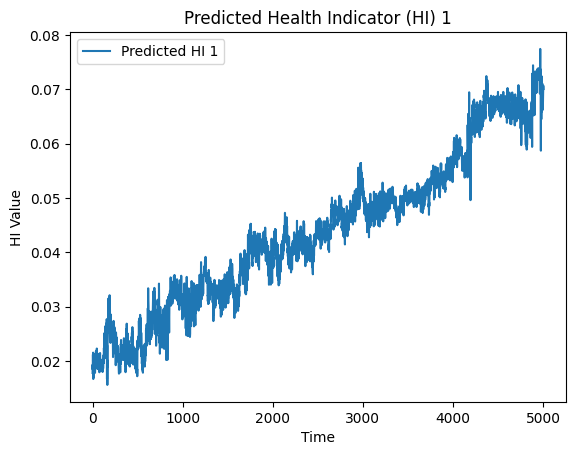

(584, 1)


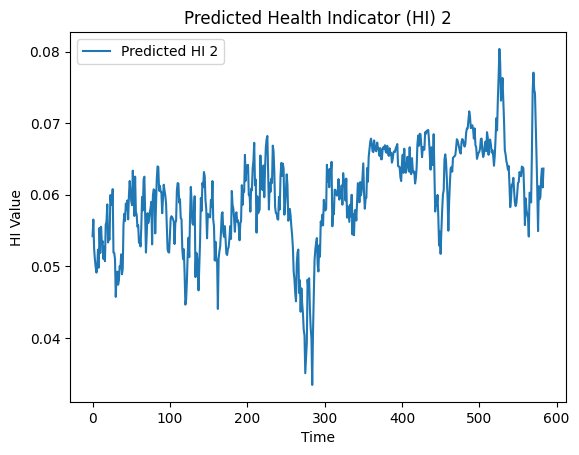

(9659, 1)


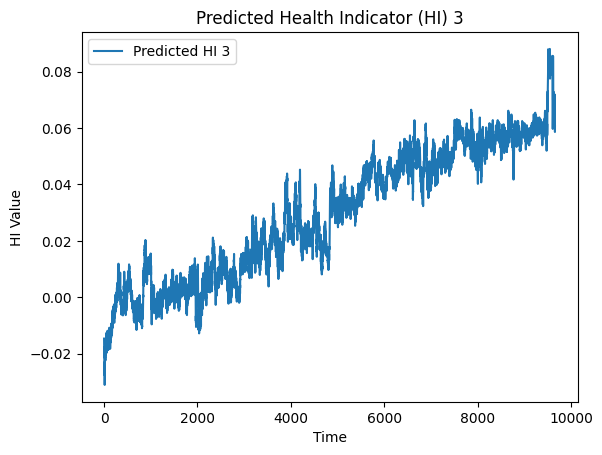

(3035, 1)


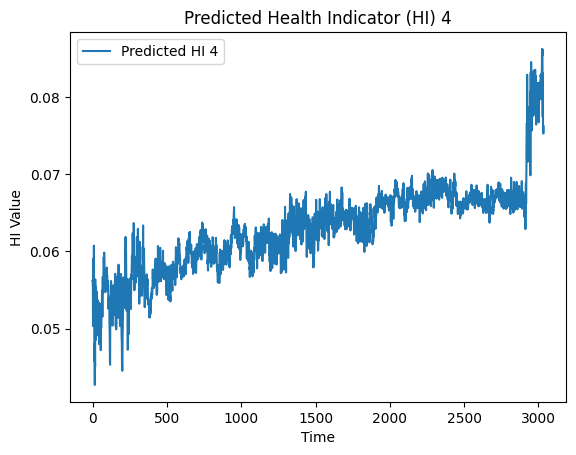

(5792, 1)


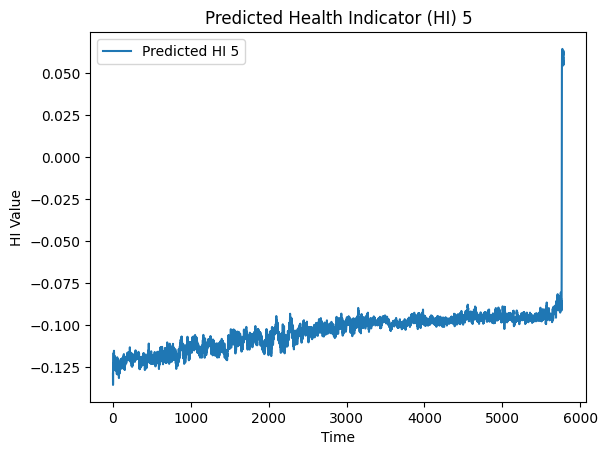

(31, 1)


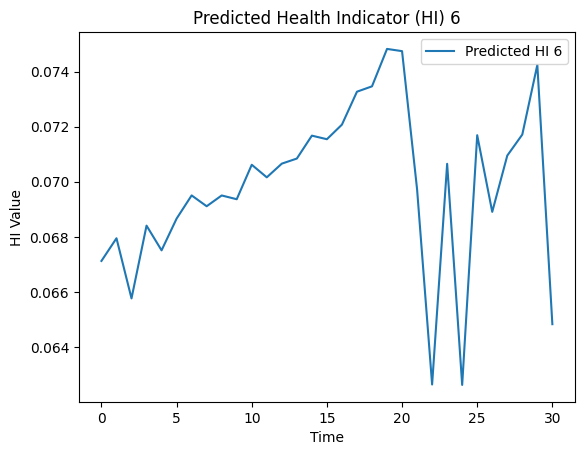

(3507, 1)


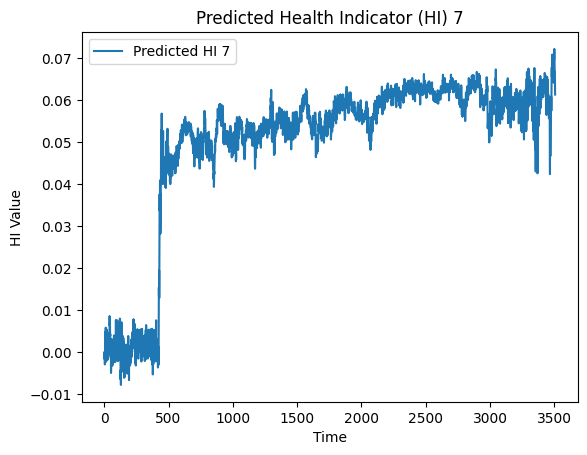

(794, 1)


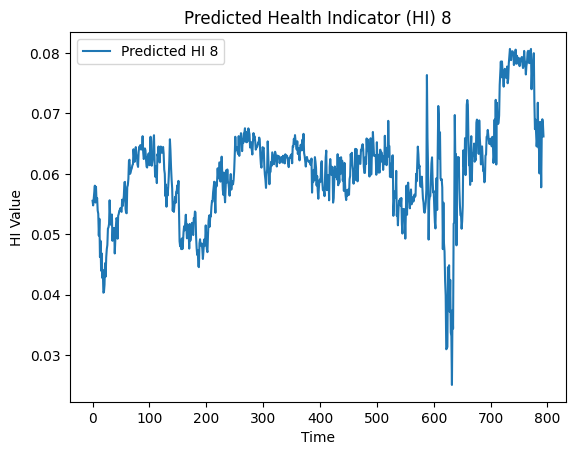

(9503, 1)


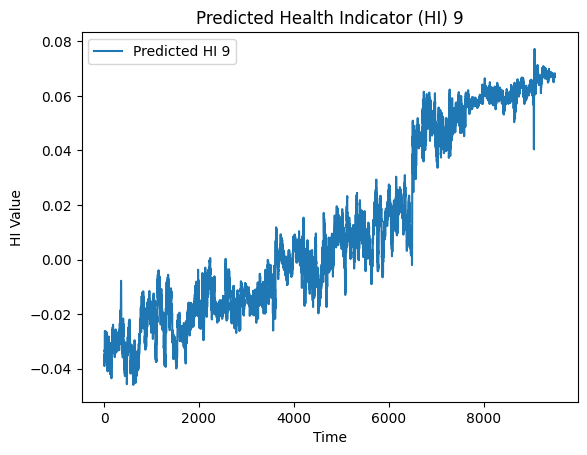

(911, 1)


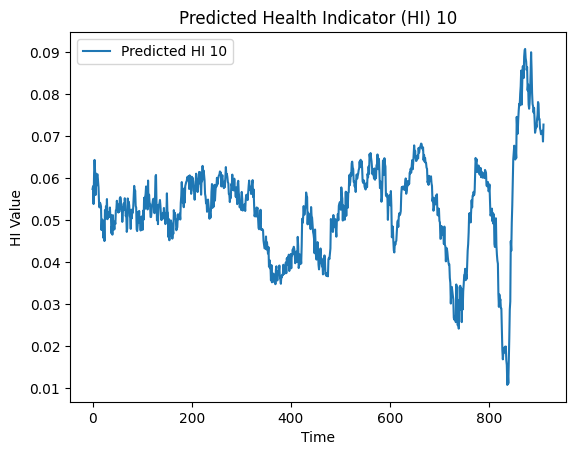

(10256, 1)


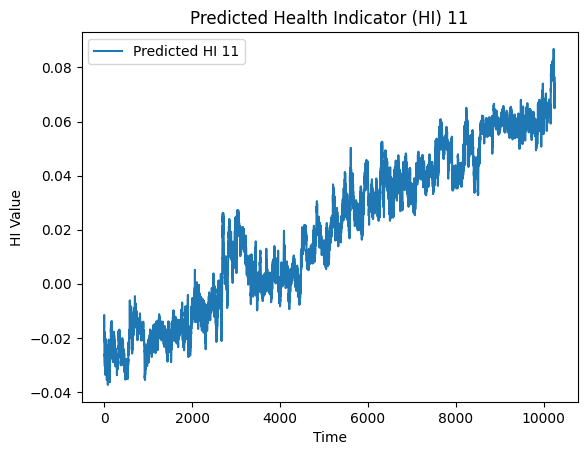

(6378, 1)


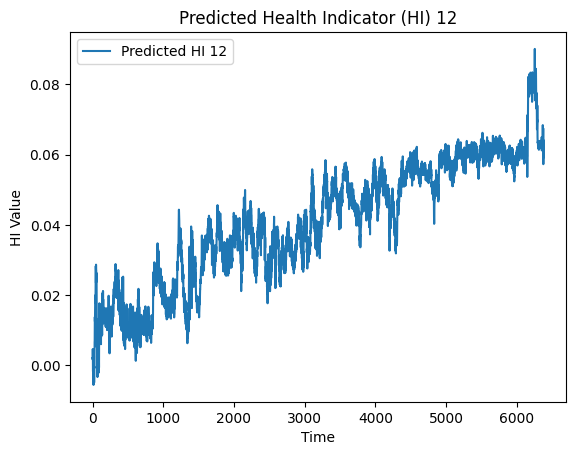

(1461, 1)


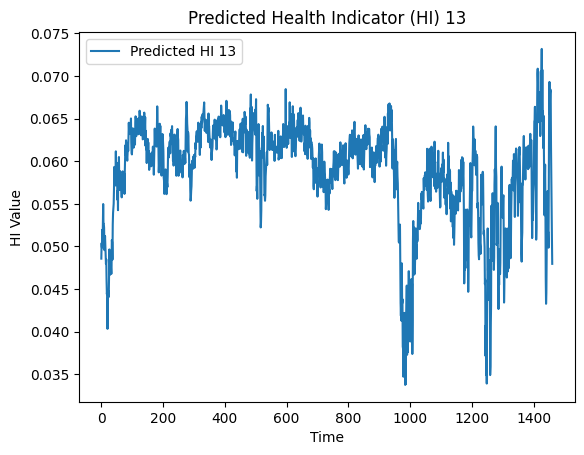

(35, 1)


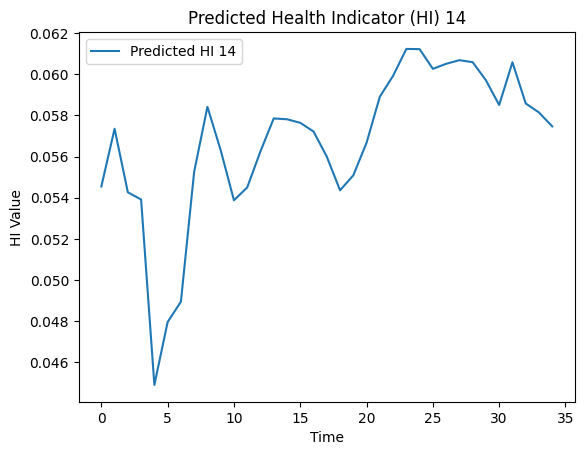

(24500, 1)


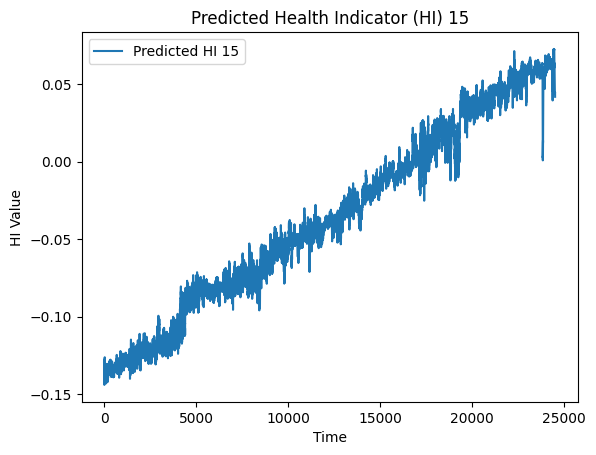

(189, 1)


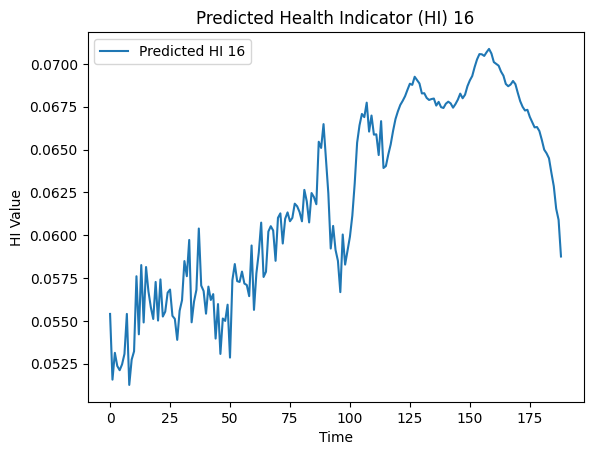

(6374, 1)


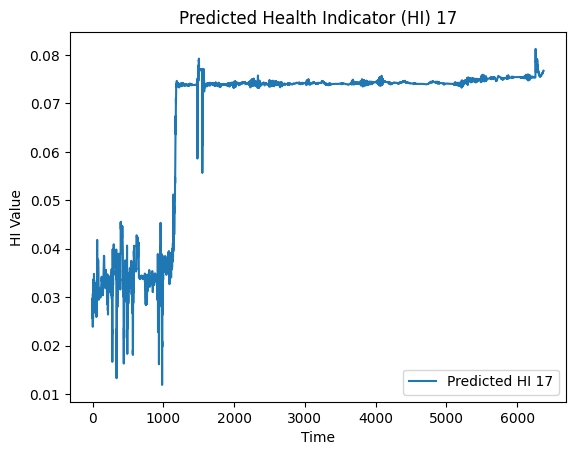

In [10]:
for i, z in enumerate(zAll):
    print(z.shape)
    plt.figure()
    plt.plot(z, label=f'Predicted HI {i+1}')
    plt.title(f'Predicted Health Indicator (HI) {i+1}')
    plt.xlabel('Time')
    plt.ylabel('HI Value')
    plt.legend()
    plt.show()
